In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

# Load the movies data with 'latin1' encoding
movies = pd.read_csv('movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin1')

# Load the ratings data with 'latin1' encoding
ratings = pd.read_csv('ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin1')

# Load the users data with 'latin1' encoding
users = pd.read_csv('users.dat', sep='::', names=['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code'], engine='python', encoding='latin1')

# Merge the ratings and users DataFrames
merged = pd.merge(pd.merge(ratings, users), movies)

# Split the genres column and create a new entry for each genre
merged = merged.assign(Genres = merged['Genres'].str.split('|')).explode('Genres')

# get the unique genres
genres = merged['Genres'].unique()

# Map each genre to an index
genre_to_index = {genre: i for i, genre in enumerate(genres)}

# Initialize the counts and averages
counts = {genre: 0 for genre in genres}
averages = {genre: 0 for genre in genres}

# Initialize the parameters of the Beta distribution for each arm
alpha = {genre: 1 for genre in genres}
beta = {genre: 1 for genre in genres}

# Calculate the frequency of each rating for each genre
rating_freq = merged.groupby('Genres')['Rating'].value_counts(normalize=True)

# Pre-calculate the ratings and probabilities arrays for each genre
rating_dist = {genre: (rating_freq[genre].index, rating_freq[genre].values)
               for genre in rating_freq.index.levels[0]}

def pull_arm(chosen_genre):
    # Check if there are any movies of this genre left
    if chosen_genre not in rating_dist:
        return 0

    # Sample a rating from the pre-calculated distribution
    ratings, probabilities = rating_dist[chosen_genre]
    reward = ratings[np.random.multinomial(1, probabilities).argmax()]

    return reward

In [ ]:
# Code for TS algorithm
def run_experiment_TS(n, num_experiments, num_arms):
    # Initialize the cumulative regret
    cumulative_regret_TS = np.zeros((num_experiments, n))

    # Run the Thompson Sampling algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}
        cumulative_regret_TS[experiment] = np.zeros(n)

        # Initialize by choosing each arm once
        for t in range(num_arms):
            chosen_arm = genres[t]
            reward = pull_arm(chosen_arm)
            counts[chosen_arm] += 1
            averages[chosen_arm] = reward

        # Update the distributions and choose the arm with the highest sample
        for t in range(num_arms, n):
            samples = {genre: np.random.normal(loc=averages[genre], scale=np.sqrt(4/(counts[genre]))) for genre in genres}
            chosen_arm = max(samples, key=samples.get)
            reward = pull_arm(chosen_arm)
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]

            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward

            # Store the cumulative regret
            cumulative_regret_TS[experiment, t] = cumulative_regret_TS[experiment, t-1] + regret       
            
    avg_regret_TS = np.mean(cumulative_regret_TS, axis=0)
    std_dev_TS = np.std(cumulative_regret_TS, axis=0)    
    return cumulative_regret_TS, avg_regret_TS, std_dev_TS

In [ ]:
# Code for UCB algorithm
def run_experiment_UCB(n, num_experiments, num_arms):

    B = 4  # Constant for adjusting the degree of exploration

    cumulative_regret_UCB = np.zeros((num_experiments, n+1))

    # Run the UCB algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}

        for t in range(1, n+1):
            # Calculate the UCB index for each arm
            ucb_indices = {genre: averages[genre] + B * np.sqrt((4 * np.log(n)) / (1 + counts[genre])) for genre in genres}
            
            # Choose the arm with the highest UCB index
            chosen_arm = max(ucb_indices, key=ucb_indices.get)
            
            # Pull the chosen arm and get the reward
            reward = pull_arm(chosen_arm)
            
            # Update the counts and averages
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]
            
            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward
            
            # Store the cumulative regret
            cumulative_regret_UCB[experiment, t] = cumulative_regret_UCB[experiment, t-1] + regret

    avg_regret_UCB = np.mean(cumulative_regret_UCB, axis=0)
    std_dev_UCB = np.std(cumulative_regret_UCB, axis=0)

    return cumulative_regret_UCB, avg_regret_UCB, std_dev_UCB



In [ ]:
# Code for ETC algorithm
def run_experiment_ETC(n, num_experiments, num_arms):
    # Set the length of the exploration phase
    m = n // (10 * num_arms) # Use integer division to ensure m is an integer

    cumulative_regret_ETC = np.zeros((num_experiments, n))


    # Run the ETC algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}

        # Exploration phase
        for t in range(m * num_arms):
            chosen_arm = genres[t % num_arms]  # Cycle through the arms
            reward = pull_arm(chosen_arm)
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]

            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward

            # Store the cumulative regret
            cumulative_regret_ETC[experiment, t] = (cumulative_regret_ETC[experiment, t-1] if t > 0 else 0) + regret

        # Exploitation phase
        best_arm = max(averages, key=averages.get)
        for t in range(m * num_arms, n):
            reward = pull_arm(best_arm)
            counts[best_arm] += 1
            averages[best_arm] = ((averages[best_arm] * (counts[best_arm] - 1)) + reward) / counts[best_arm]

            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward

            # Store the cumulative regret
            cumulative_regret_ETC[experiment, t] = cumulative_regret_ETC[experiment, t-1] + regret

    avg_regret_ETC = np.mean(cumulative_regret_ETC, axis=0)
    std_dev_ETC = np.std(cumulative_regret_ETC, axis=0)

    return cumulative_regret_ETC, avg_regret_ETC, std_dev_ETC


In [ ]:
# Define the horizon and the number of experiments
n = 50000
num_experiments = 10
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)


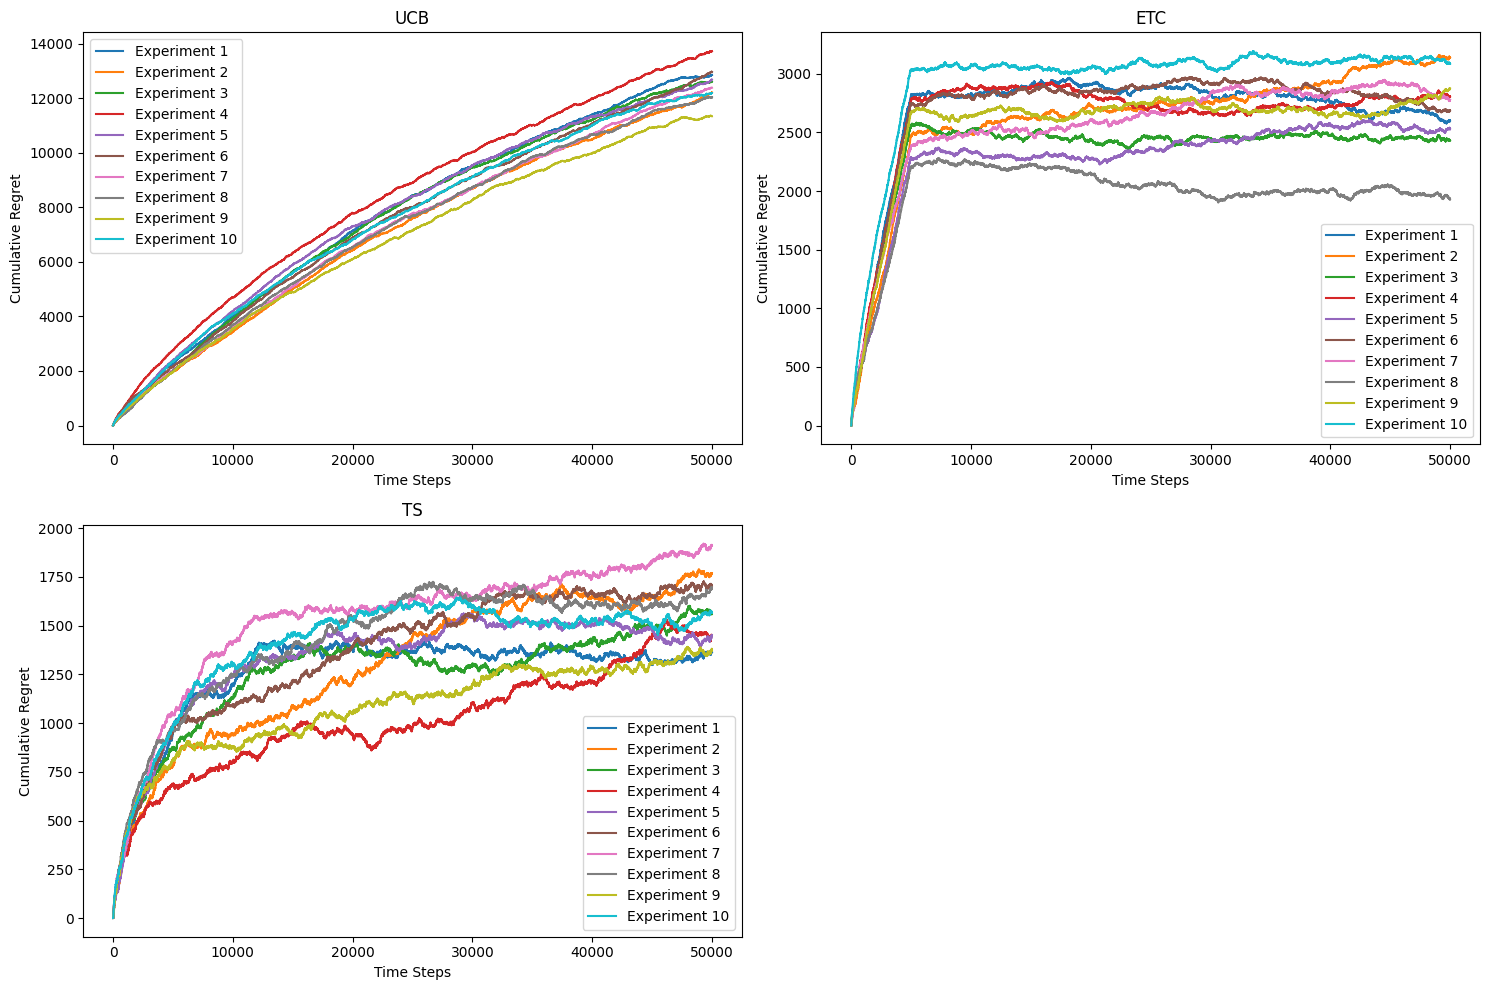

In [ ]:
# Plot for Ploblem 1-1

fig, axs = plt.subplots(2, 2, figsize=(15, 10))  # Create a 2x2 grid of subplots

# Plot the cumulative regret for each algorithm
for experiment in range(num_experiments):
    axs[0, 0].plot(UCB_regret[experiment], label=f'Experiment {experiment+1}')
    axs[0, 1].plot(ETC_regret[experiment], label=f'Experiment {experiment+1}')
    axs[1, 0].plot(TS_regret[experiment], label=f'Experiment {experiment+1}')

# Set labels and titles for each subplot
axs[0, 0].set_title('UCB')
axs[0, 0].set_xlabel('Time Steps')
axs[0, 0].set_ylabel('Cumulative Regret')

axs[0, 1].set_title('ETC')
axs[0, 1].set_xlabel('Time Steps')
axs[0, 1].set_ylabel('Cumulative Regret')

axs[1, 0].set_title('TS')
axs[1, 0].set_xlabel('Time Steps')
axs[1, 0].set_ylabel('Cumulative Regret')

# Remove the unused subplot
fig.delaxes(axs[1,1])

# Add legends
axs[0, 0].legend()
axs[0, 1].legend()
axs[1, 0].legend()

# Display the plot
plt.tight_layout()
plt.show()


From the graph above we can observe that for each algorithm, although the experimental data is biased each time, it shows a monotonous increase within a reasonable range. The TS algorithm has the less cumulative regret over time, and the UCB algorithm has the less variation across experiment.

In [ ]:
# Define the horizon and the number of experiments
n = 50000
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_50000_100 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_50000_100 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

In [ ]:

def plot_graph(avg_regrets, std_devs, title):

    # Define marker shapes for each algorithm
    markers = {
        'UCB': 'o',
        'ETC': 's',  # square
        'TS': '^',  # triangle
    }

    colors = {
        'UCB': 'blue',
        'ETC': 'green',
        'TS': 'red'
    }
    # Plot the average regret for each algorithm with error bars
    for algorithm in ['UCB', 'ETC', 'TS']:
        plt.errorbar(range(len(avg_regrets[algorithm])), avg_regrets[algorithm], yerr=std_devs[algorithm], label=algorithm, elinewidth= 0.1, fmt=markers[algorithm], alpha=0.1, markersize=4, capsize=2, capthick= 0.5)

    plt.xlabel('Time Steps')
    plt.ylabel('Average Regret')
    plt.title(title)  # Title of the plot
    plt.legend()

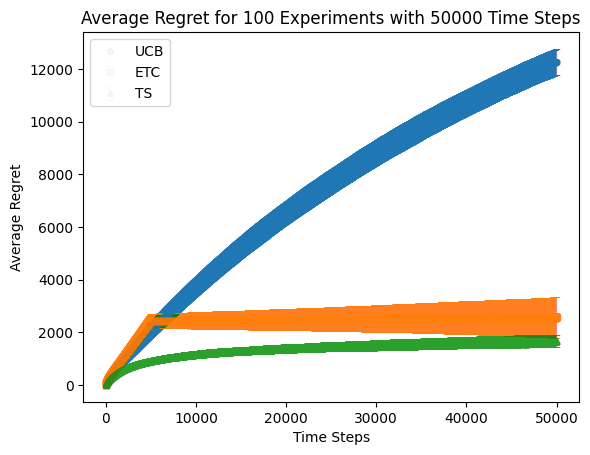

In [ ]:
plot_graph(avg_regrets_50000_100, std_devs_50000_100, 'Average Regret for 100 Experiments with 50000 Time Steps')

In [ ]:
# Problem 2
# n = 500
# Define the horizon and the number of experiments
n = 500
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret_500, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_500 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_500 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

In [ ]:
# Problem 2
# n = 5000
# Define the horizon and the number of experiments
n = 5000
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_5000 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_5000 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

In [ ]:
# Problem 2
# n = 50000
# Define the horizon and the number of experiments
n = 50000
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_50000 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_50000 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

In [ ]:
# Problem 2
# n = 500000
# Define the horizon and the number of experiments
n = 500000
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_500000 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_500000 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

In [ ]:
# Problem 2
# n = 5000000
# Define the horizon and the number of experiments
n = 5000000
num_experiments = 100
num_arms = len(genres)

np.random.seed(122)
# Run the ETC algorithm
ETC_regret, ETC_avg, ETC_sd = run_experiment_ETC(n, num_experiments, num_arms)

# Run the UCB algorithm
UCB_regret, UCB_avg, UCB_sd = run_experiment_UCB(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret, TS_avg, TS_sd = run_experiment_TS(n, num_experiments, num_arms)

avg_regrets_5000000 = {
    'UCB': UCB_avg,
    'ETC': ETC_avg,
    'TS': TS_avg
}

std_devs_5000000 = {
    'UCB': UCB_sd,
    'ETC': ETC_sd,
    'TS': TS_sd
}

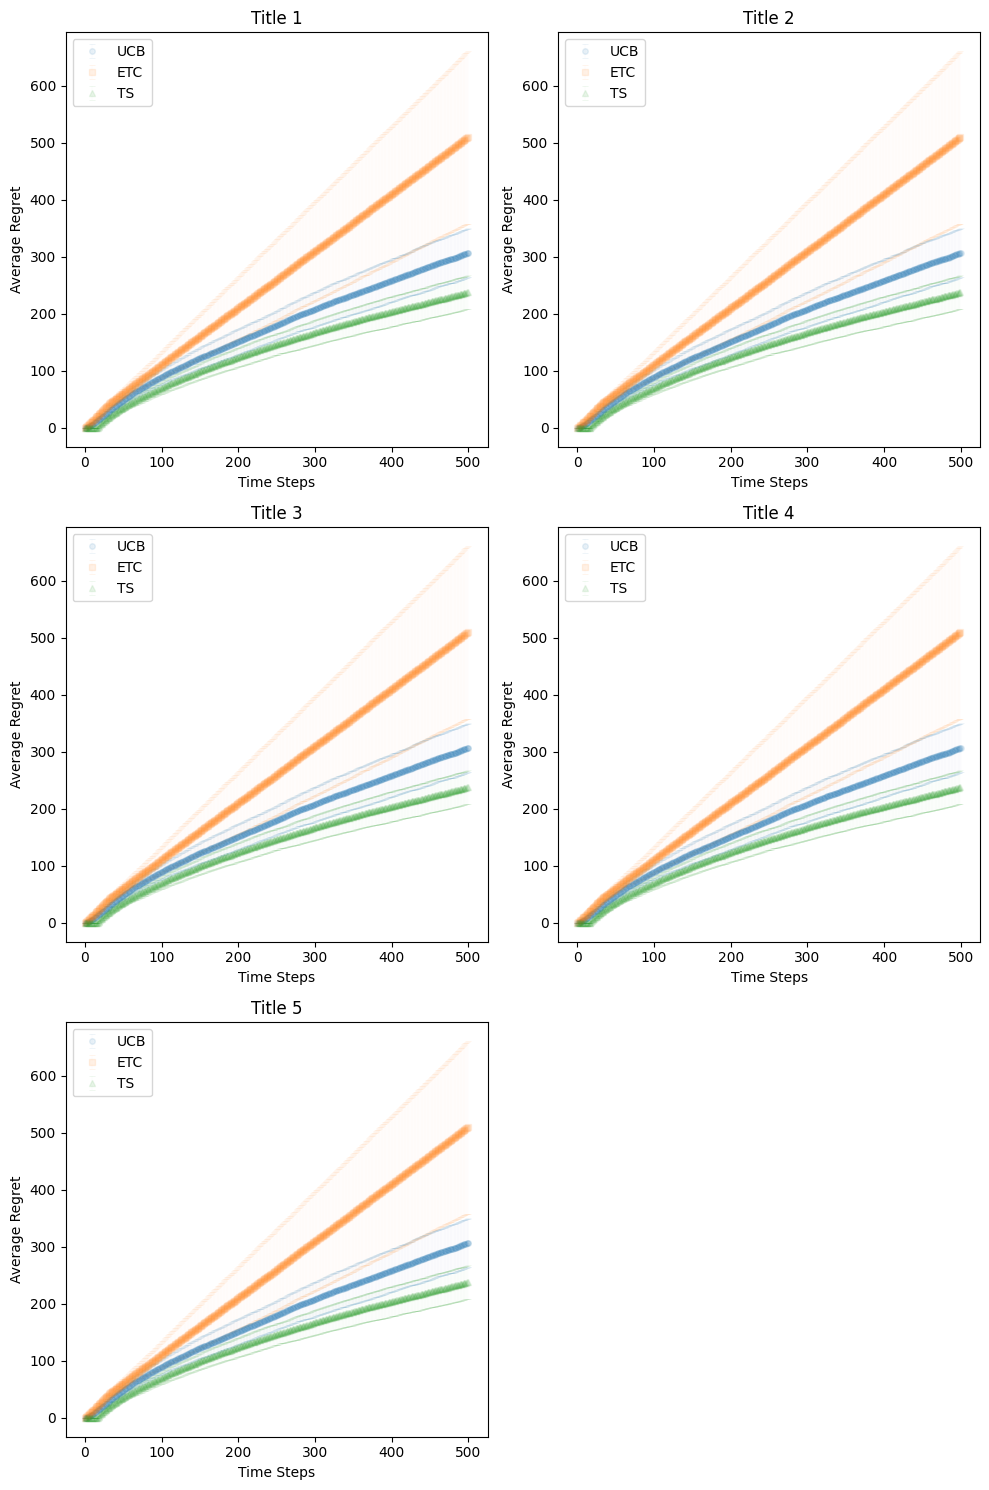

In [ ]:
# Plot for Ploblem 2

fig, axs = plt.subplots(3, 2, figsize=(10, 15))  # Create a grid of 3 rows and 2 columns

# Assume we have the average regrets and standard deviations for each algorithm for 6 different cases
avg_regrets_list = [avg_regrets_500, avg_regrets_5000, avg_regrets_50000, avg_regrets_500000, avg_regrets_5000000]
std_devs_list = [std_devs_500, std_devs_500, std_devs_500, std_devs_500, std_devs_500]
titles = ['Average Regret for 100 Experiments with 500 Time Steps', 'Average Regret for 100 Experiments with 5000 Time Steps', 'Average Regret for 100 Experiments with 50000 Time Steps', 'Average Regret for 100 Experiments with 500000 Time Steps', 'Average Regret for 100 Experiments with 5000000 Time Steps']

# Flatten the axs array for easy iteration
axs = axs.flatten()

for i in range(5):
    plt.sca(axs[i])  # Set the current Axes to ax
    plot_graph(avg_regrets_list[i], std_devs_list[i], titles[i])

# Remove the last empty subplot
fig.delaxes(axs[-1])


plt.tight_layout()  # Adjust the layout to prevent overlaps
plt.show()

In [12]:
# Question 3
# Define the horizon and the number of experiments
# Code for ETC algorithm_Q3
def run_experiment_ETC_Q3(n, num_experiments, num_arms, param):

    cumulative_regret_ETC = np.zeros((num_experiments, n))


    # Run the ETC algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}

        # Exploration phase
        for t in range(param):
            chosen_arm = genres[t % num_arms]  # Cycle through the arms
            reward = pull_arm(chosen_arm)
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]

            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward

            # Store the cumulative regret
            cumulative_regret_ETC[experiment, t] = (cumulative_regret_ETC[experiment, t-1] if t > 0 else 0) + regret

        # Exploitation phase
        best_arm = max(averages, key=averages.get)
        for t in range(param, n):
            reward = pull_arm(best_arm)
            counts[best_arm] += 1
            averages[best_arm] = ((averages[best_arm] * (counts[best_arm] - 1)) + reward) / counts[best_arm]

            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward

            # Store the cumulative regret
            cumulative_regret_ETC[experiment, t] = cumulative_regret_ETC[experiment, t-1] + regret

    avg_regret_ETC = np.mean(cumulative_regret_ETC, axis=0)
    std_dev_ETC = np.std(cumulative_regret_ETC, axis=0)

    return cumulative_regret_ETC, avg_regret_ETC, std_dev_ETC



In [15]:
np.random.seed(122)
n = 50000
num_experiments = 100
num_arms = len(genres)

# m*k = 50
regret, avg_regret, std_dev = run_experiment_ETC_Q3(n, num_experiments, num_arms, 50)
avg_regrets_50_Q3 = {
    'ETC': avg_regret
}

std_devs_50_Q3 = {
    'ETC': std_dev
}

# m*k = 500
regret, avg_regret, std_dev = run_experiment_ETC_Q3(n, num_experiments, num_arms, 500)
avg_regrets_500_Q3 = {
    'ETC': avg_regret
}

std_devs_500_Q3 = {
    'ETC': std_dev
}

# m*k = 2000
regret, avg_regret, std_dev = run_experiment_ETC_Q3(n, num_experiments, num_arms, 2000)
avg_regrets_2000_Q3 = {
    'ETC': avg_regret
}

std_devs_2000_Q3 = {
    'ETC': std_dev
}

# m*k = 5000
regret, avg_regret, std_dev = run_experiment_ETC_Q3(n, num_experiments, num_arms, 5000)
avg_regrets_5000_Q3 = {
    'ETC': avg_regret
}

std_devs_5000_Q3 = {
    'ETC': std_dev
}

# m*k = 10000
regret, avg_regret, std_dev = run_experiment_ETC_Q3(n, num_experiments, num_arms, 10000)
avg_regrets_10000_Q3 = {
    'ETC': avg_regret
}

std_devs_10000_Q3 = {
    'ETC': std_dev
}


In [19]:
def plot_graph_Q3(avg_regrets, std_devs, title):


    for algorithm in [ 'ETC']:
        plt.errorbar(range(len(avg_regrets[algorithm])), avg_regrets[algorithm], yerr=std_devs[algorithm], label=algorithm, elinewidth= 0.1, alpha=0.1, markersize=4, capsize=2, capthick= 0.5)

    plt.xlabel('Time Steps')
    plt.ylabel('Average Regret')
    plt.title(title)  # Title of the plot
    plt.legend()

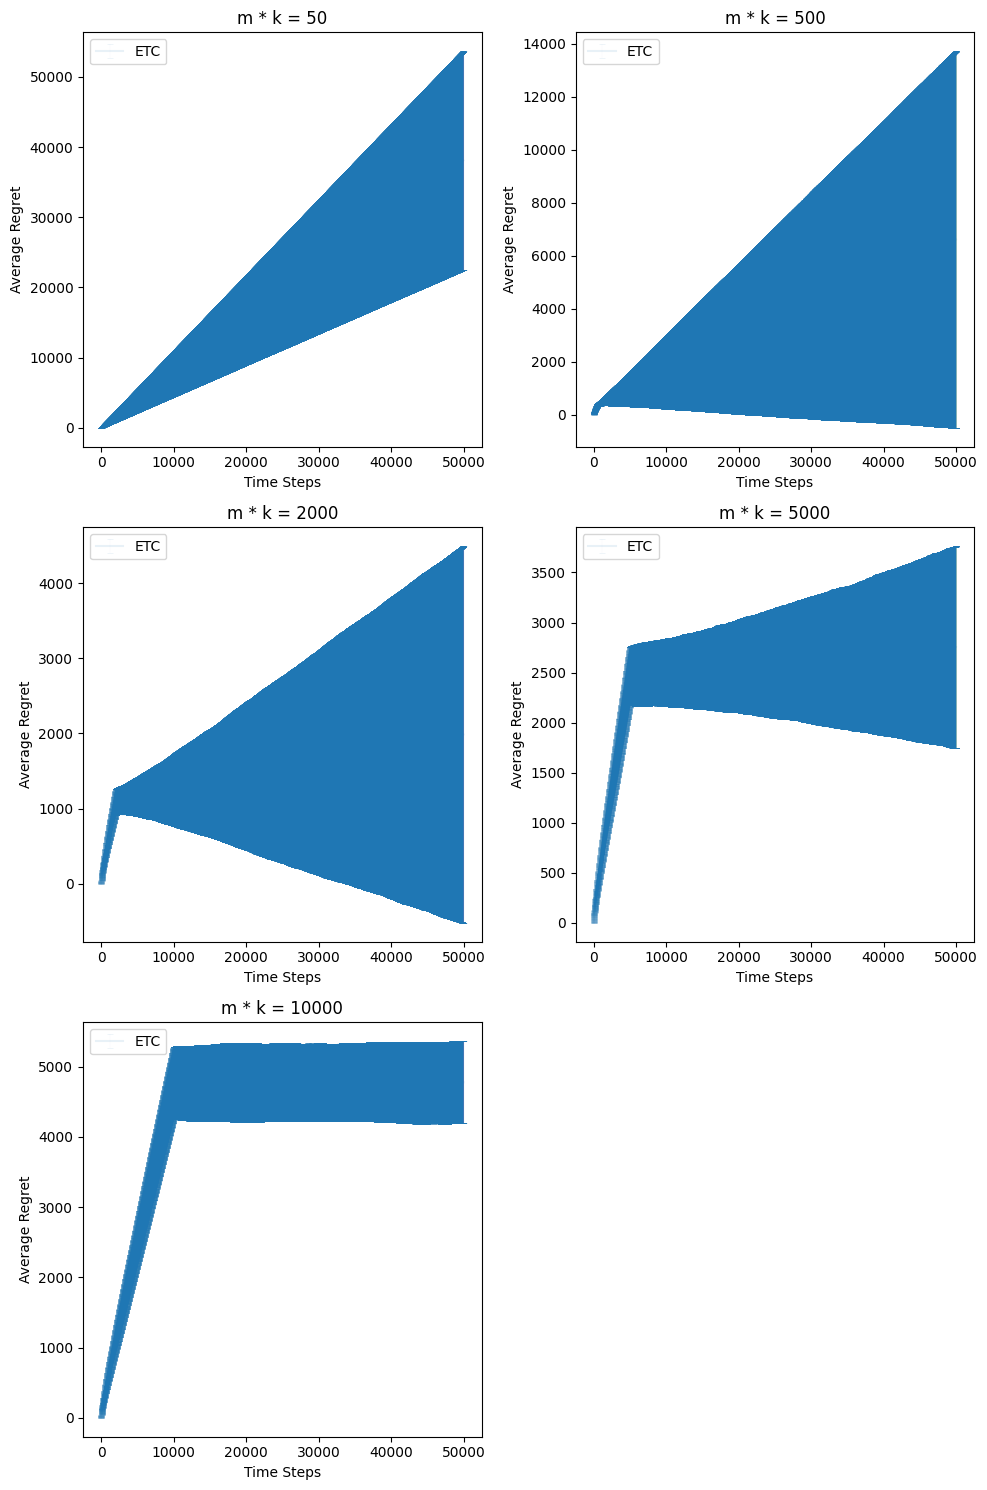

In [20]:
# Plot for Ploblem 3

fig, axs = plt.subplots(3, 2, figsize=(10, 15))  # Create a grid of 3 rows and 2 columns

# Assume we have the average regrets and standard deviations for each algorithm for 6 different cases
avg_regrets_list = [avg_regrets_50_Q3, avg_regrets_500_Q3, avg_regrets_2000_Q3, avg_regrets_5000_Q3, avg_regrets_10000_Q3]
std_devs_list = [std_devs_50_Q3, std_devs_500_Q3, std_devs_2000_Q3, std_devs_5000_Q3, std_devs_10000_Q3]
titles = ['m * k = 50', 'm * k = 500', 'm * k = 2000', 'm * k = 5000', 'm * k = 10000']

# Flatten the axs array for easy iteration
axs = axs.flatten()

for i in range(5):
    plt.sca(axs[i])  # Set the current Axes to ax
    plot_graph_Q3(avg_regrets_list[i], std_devs_list[i], titles[i])

# Remove the last empty subplot
fig.delaxes(axs[-1])


plt.tight_layout()  # Adjust the layout to prevent overlaps
plt.show()

The result indicated that the ETC algorithm performs best when m * k = 5000, which is 10% of n. Before m * k = 5000, the average regret decreases as m * k increase. After m * k > 5000, the average regret increases; this may be because as we explore more, the average regret will inevitably increase. Compared to the UCB and TS algorithms in Q1, the performance of ETC is better than UCB and worsen than TS.

In [51]:
# Question 4

def run_optimal_UCB(n, num_experiments, num_arms):

    B = 4  # Constant for adjusting the degree of exploration

    cumulative_regret_UCB = np.zeros((num_experiments, n+1))

    # Run the UCB algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}

        for t in range(1, n+1):
            # Calculate f(t)
            f_t = 1 + t * (np.log(t))**2
            
            # Calculate the UCB index for each arm
            ucb_indices = {genre: averages[genre] + B * np.sqrt((2 * np.log(f_t)) / (1 + counts[genre])) for genre in genres}
            
            # Choose the arm with the highest UCB index
            chosen_arm = max(ucb_indices, key=ucb_indices.get)
            
            # Pull the chosen arm and get the reward
            reward = pull_arm(chosen_arm)
            
            # Update the counts and averages
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]
            
            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward
            
            # Store the cumulative regret
            cumulative_regret_UCB[experiment, t] = cumulative_regret_UCB[experiment, t-1] + regret

    avg_regret_UCB = np.mean(cumulative_regret_UCB, axis=0)
    std_dev_UCB = np.std(cumulative_regret_UCB, axis=0)

    return cumulative_regret_UCB, avg_regret_UCB, std_dev_UCB


In [50]:
# Code for Standard UCB algorithm
def run_standard_UCB(n, num_experiments, num_arms, lota):

    B = 4  # Constant for adjusting the degree of exploration

    cumulative_regret_UCB = np.zeros((num_experiments, n+1))

    # Run the UCB algorithm
    for experiment in range(num_experiments):
        # Reset the counts, averages, and cumulative regret at the start of each experiment
        counts = {genre: 0 for genre in genres}
        averages = {genre: 0 for genre in genres}

        for t in range(1, n+1):
            # Calculate the UCB index for each arm
            ucb_indices = {genre: averages[genre] + B * np.sqrt((lota * np.log(n)) / (1 + counts[genre])) for genre in genres}
            
            # Choose the arm with the highest UCB index
            chosen_arm = max(ucb_indices, key=ucb_indices.get)
            
            # Pull the chosen arm and get the reward
            reward = pull_arm(chosen_arm)
            
            # Update the counts and averages
            counts[chosen_arm] += 1
            averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]
            
            # Calculate the regret
            optimal_reward = max(averages.values())
            regret = optimal_reward - reward
            
            # Store the cumulative regret
            cumulative_regret_UCB[experiment, t] = cumulative_regret_UCB[experiment, t-1] + regret

    avg_regret_UCB = np.mean(cumulative_regret_UCB, axis=0)
    std_dev_UCB = np.std(cumulative_regret_UCB, axis=0)

    return cumulative_regret_UCB, avg_regret_UCB, std_dev_UCB



In [38]:
np.random.seed(122)
n = 50000
num_experiments = 100
num_arms = len(genres)

# Run the optimal UCB algorithm
UCB_regret_Q4, UCB_avg_Q4, UCB_sd_Q4 = run_optimal_UCB(n, num_experiments, num_arms)

# Run the standard UCB algorithm with lota = 1
UCB_regret_1_Q4, UCB_avg_1_Q4, UCB_sd_1_Q4 = run_standard_UCB(n, num_experiments, num_arms, 1)

# Run the standard UCB algorithm with lota = 2
UCB_regret_2_Q4, UCB_avg_2_Q4, UCB_sd_2_Q4 = run_standard_UCB(n, num_experiments, num_arms, 2)

# Run the standard UCB algorithm with lota = 4
UCB_regret_4_Q4, UCB_avg_4_Q4, UCB_sd_4_Q4 = run_standard_UCB(n, num_experiments, num_arms, 4)

avg_regrets_Q4 = {
    'Optimal UCB': UCB_avg_Q4,
    'Standard UCB (lota = 1)': UCB_avg_1_Q4,
    'Standard UCB (lota = 2)': UCB_avg_2_Q4,
    'Standard UCB (lota = 4)': UCB_avg_4_Q4
}

std_devs_Q4 = {
    'Optimal UCB': UCB_sd_Q4,
    'Standard UCB (lota = 1)': UCB_sd_1_Q4,
    'Standard UCB (lota = 2)': UCB_sd_2_Q4,
    'Standard UCB (lota = 4)': UCB_sd_4_Q4
}


In [41]:
def plot_graph_Q4(avg_regrets, std_devs, title):

    for algorithm in ['Optimal UCB', 'Standard UCB (lota = 1)', 'Standard UCB (lota = 2)', 'Standard UCB (lota = 4)']:
        plt.errorbar(range(len(avg_regrets[algorithm])), avg_regrets[algorithm], yerr=std_devs[algorithm], label=algorithm, elinewidth= 0.1, alpha=0.5, markersize=4, capsize=2, capthick= 0.5)

    plt.xlabel('Time Steps')
    plt.ylabel('Average Regret')
    plt.title(title)  # Title of the plot
    plt.legend()
    plt.show()

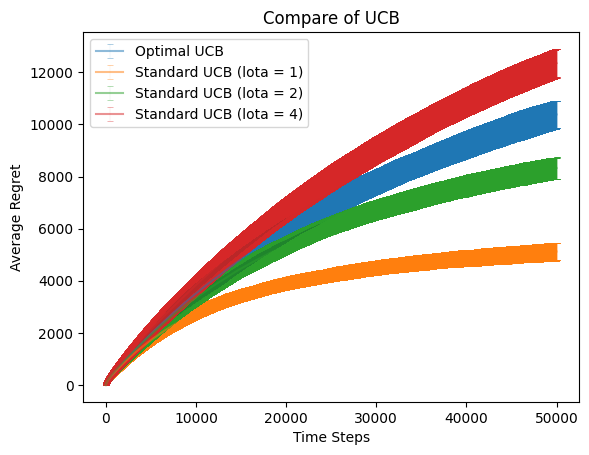

In [42]:
plot_graph_Q4(avg_regrets_Q4, std_devs_Q4, 'Compare of UCB')

The standard UCB with lota = 1 has the best performance, while the standard UCB with lota = 4 has the worst. This indicates that the performance increase while lota decreases. The performance of Optimal UCB is between standard UCB with lota = 4 and standard UCB with lota = 2.

In [52]:
# Question 5

np.random.seed(122)
n = 1000000
num_experiments = 100
num_arms = len(genres)

# Run the optimal UCB algorithm
UCB_regret_Q5, UCB_avg_Q5, UCB_sd_Q5 = run_optimal_UCB(n, num_experiments, num_arms)

# Run the ETC algorithm
ETC_regret_Q5, ETC_avg_Q5, ETC_sd_Q5 = run_experiment_ETC(n, num_experiments, num_arms)

# Run the Thompson Sampling algorithm
TS_regret_Q5, TS_avg_Q5, TS_sd_Q5 = run_experiment_TS(n, num_experiments, num_arms)

# Run the standard UCB algorithm with lota = 4
UCB_regret_4_Q5, UCB_avg_4_Q5, UCB_sd_4_Q5 = run_standard_UCB(n, num_experiments, num_arms, 4)

avg_regrets_Q5 = {
    'Optimal UCB': UCB_avg_Q5,
    'ETC': ETC_avg_Q5,
    'TS': TS_avg_Q5,
    'Standard UCB (lota = 4)': UCB_avg_4_Q5
}

std_devs_Q5 = {
    'Optimal UCB': UCB_sd_Q5,
    'ETC': ETC_sd_Q5,
    'TS': TS_sd_Q5,
    'Standard UCB (lota = 4)': UCB_sd_4_Q5
}



In [56]:
def plot_graph_Q5(avg_regrets, std_devs, title):

    for algorithm in ['Optimal UCB', 'ETC', 'TS', 'Standard UCB (lota = 4)']:
        plt.errorbar(range(len(avg_regrets[algorithm])), avg_regrets[algorithm], yerr=std_devs[algorithm], label=algorithm, elinewidth= 0.1, alpha=1, markersize=4, capsize=2, capthick= 0.5)

    plt.xlabel('Time Steps')
    plt.ylabel('Average Regret')
    plt.title(title)  # Title of the plot
    plt.legend()
    plt.show()

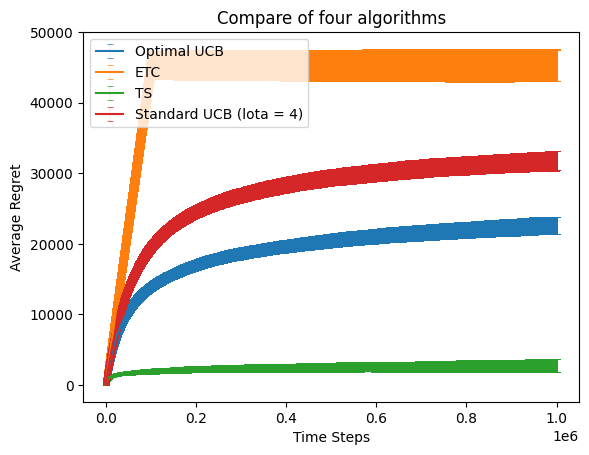

In [57]:
plot_graph_Q5(avg_regrets_Q5, std_devs_Q5, 'Compare of four algorithms')